# Ultimate Technologies Inc. — Take-Home Challenge

**Three-part analysis:** login demand, experimental design, and rider retention. Run from this directory with the supplied JSON files one level above. See README.md for the detailed methodology and caveats.

## Reproduce full analysis
The following executes all cleaning, exploratory statistics, model fitting, evaluations, and plots.

In [1]:
%run analysis.py

LOGINS 93142 invalid 0 duplicates 877 range 1970-01-01 20:12:16 1970-04-13 18:57:38 bins 9788 zero 407
DAILY {'count': 103.0, 'mean': 904.2912621359224, 'std': 347.16746343515433, 'min': 112.0, '25%': 643.0, '50%': 827.0, '75%': 1141.0, 'max': 1889.0}
WEEKDAY {'Friday': 10.561111111111112, 'Monday': 6.2133802816901404, 'Saturday': 13.45625, 'Sunday': 12.615972222222222, 'Thursday': 8.794117647058824, 'Tuesday': 6.895833333333333, 'Wednesday': 7.692708333333333}
PEAK_HOURS {22: 16.193627450980394, 1: 15.482843137254902, 23: 14.848039215686274, 0: 14.688725490196079, 2: 14.215686274509803, 11: 14.213235294117647}
RIDERS 50000 snapshot 2014-07-01 00:00:00 cutoff 2014-06-01 00:00:00 retained 18804 rate 0.37608
MISSING {'city': 0, 'trips_in_first_30_days': 0, 'signup_date': 0, 'avg_rating_of_driver': 8122, 'avg_surge': 0, 'last_trip_date': 0, 'phone': 396, 'surge_pct': 0, 'ultimate_black_user': 0, 'weekday_pct': 0, 'avg_dist': 0, 'avg_rating_by_driver': 201, 'retained': 0}
RET_CITY {'mean':

## Part 1 — Daily demand
Daily login counts reveal fluctuations across the study period.

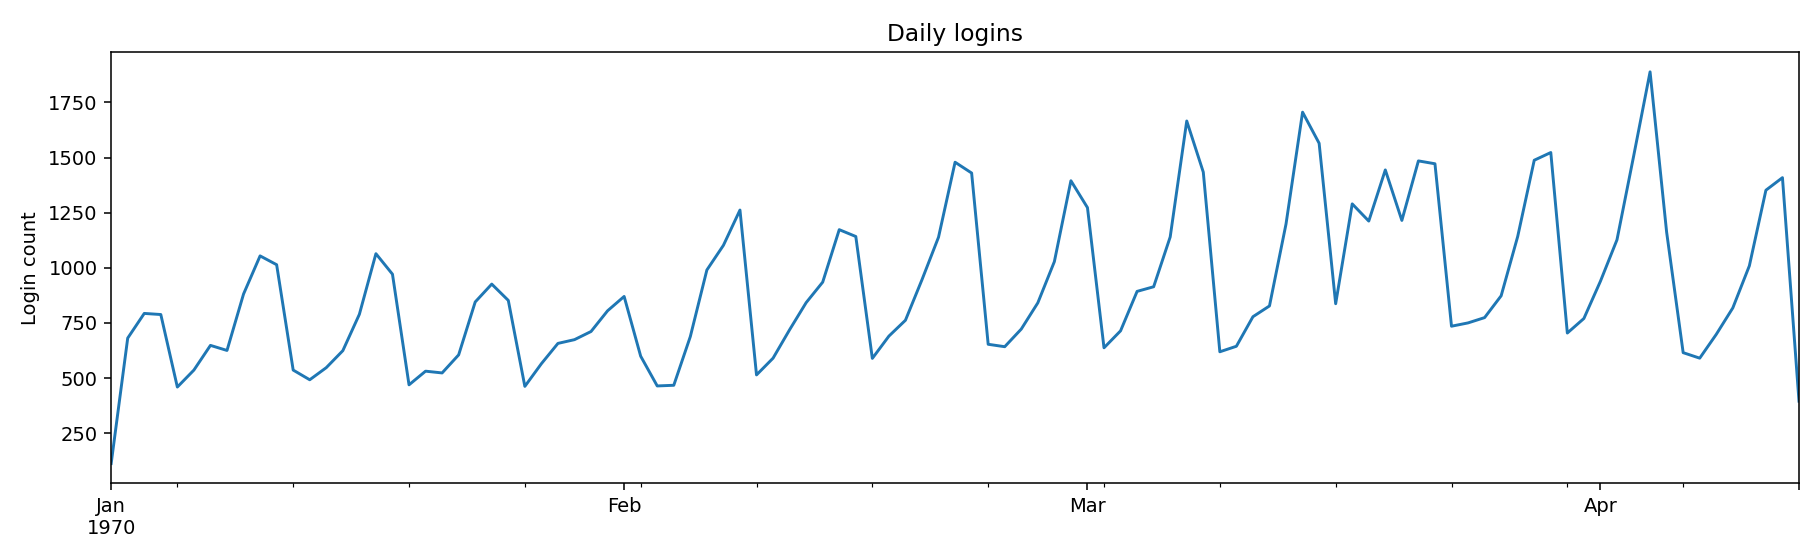

In [2]:
from IPython.display import display, Image
display(Image(filename="daily_logins.png"))

## Part 1 — Hourly demand
Demand is highest late at night and around lunchtime.

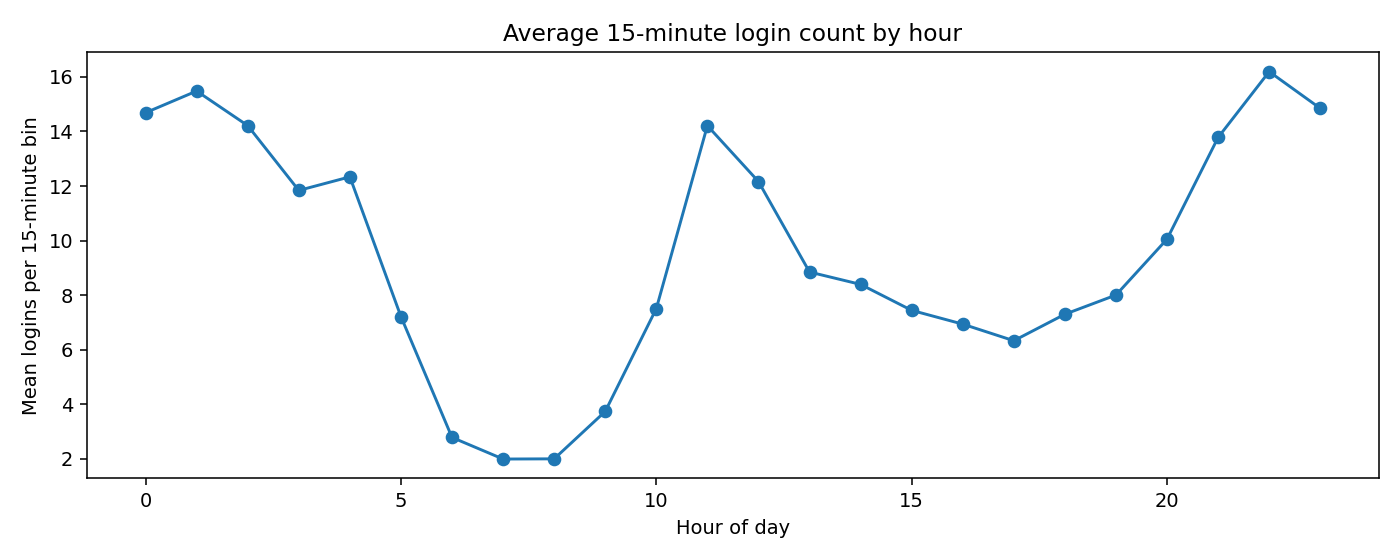

In [3]:
from IPython.display import display, Image
display(Image(filename="hourly_cycle.png"))

## Part 1 — Weekly demand
Weekend demand is stronger than early weekdays.

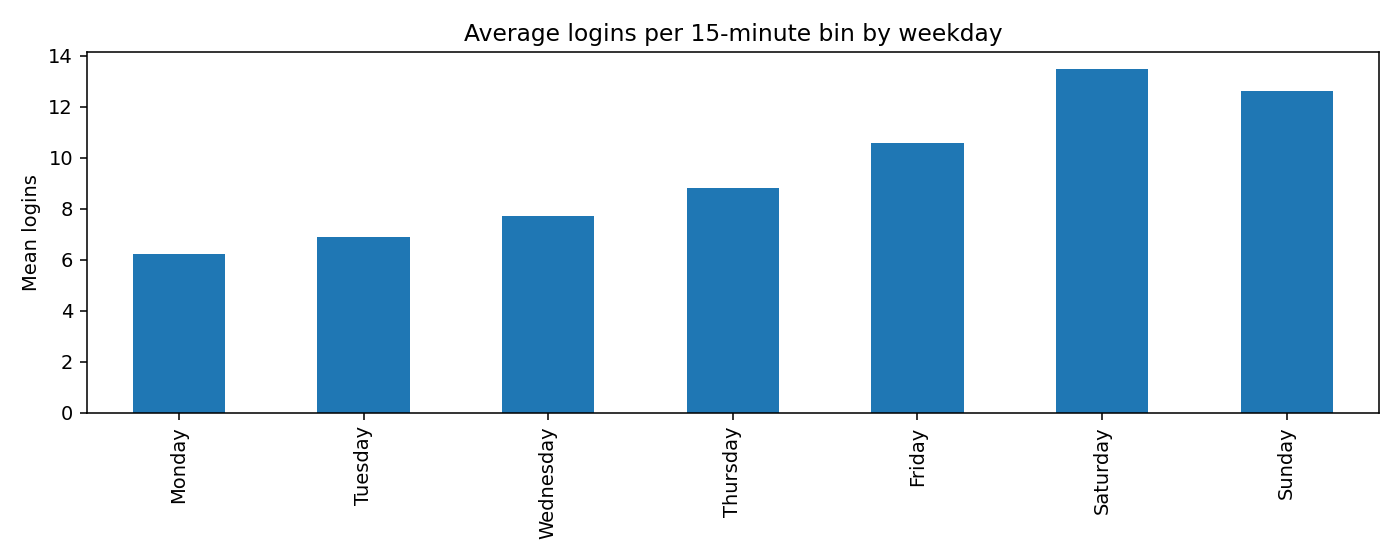

In [4]:
from IPython.display import display, Image
display(Image(filename="weekday_cycle.png"))

## Part 1 — Day/hour interaction
The heatmap shows where weekly and hourly cycles interact.

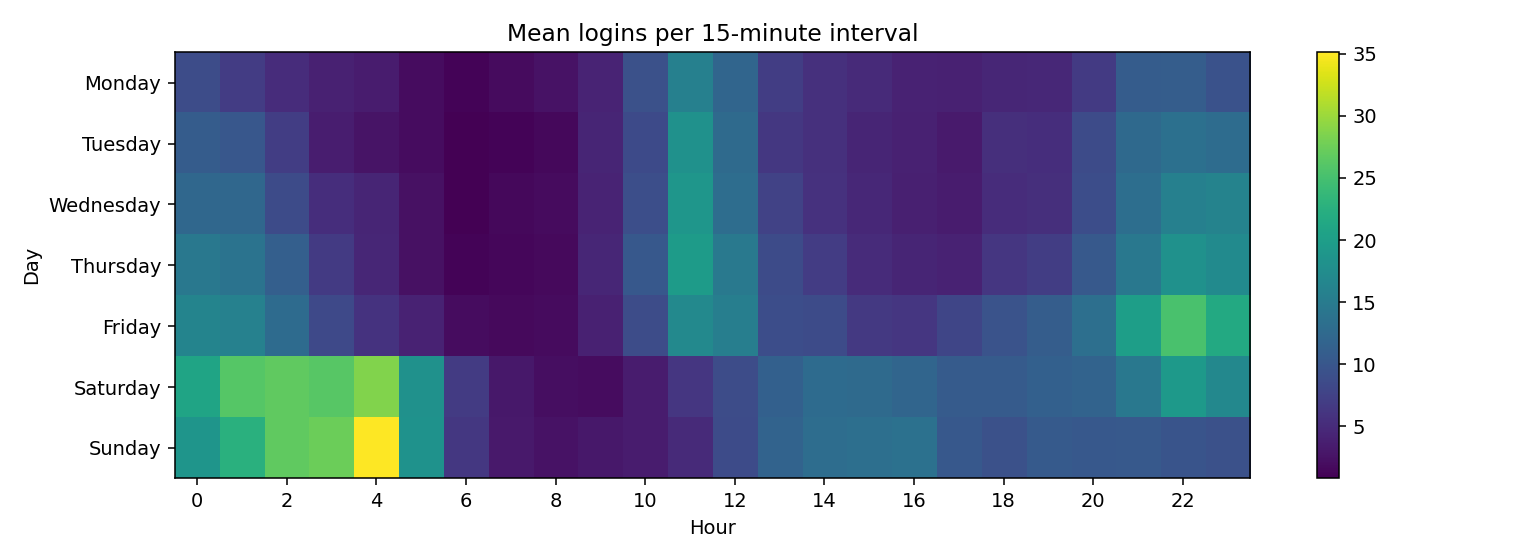

In [5]:
from IPython.display import display, Image
display(Image(filename="demand_heatmap.png"))

## Part 3 — Retention by city
City is a strong correlate of observed retention.

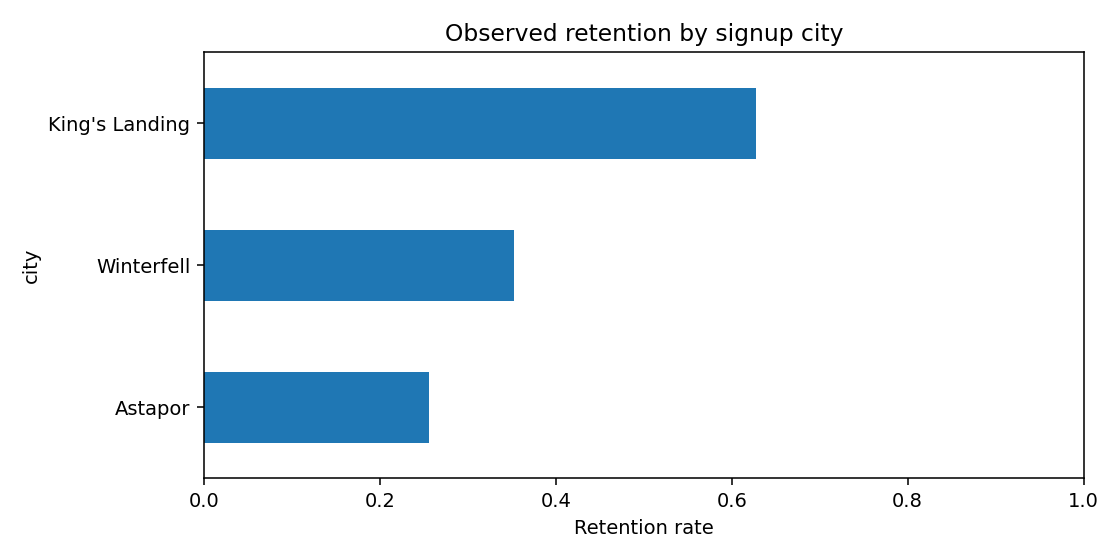

In [6]:
from IPython.display import display, Image
display(Image(filename="retention_by_city.png"))

## Part 3 — Retention by first-month trips
Early trip frequency is associated with retention.

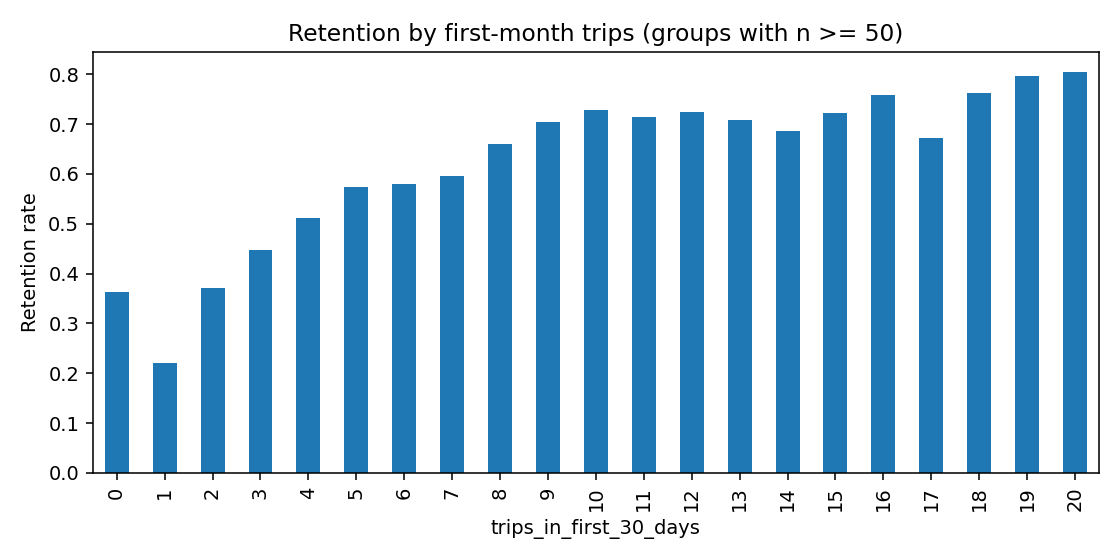

In [7]:
from IPython.display import display, Image
display(Image(filename="retention_by_trips.png"))

## Part 3 — Model comparison
Random Forest improves discrimination over logistic regression.

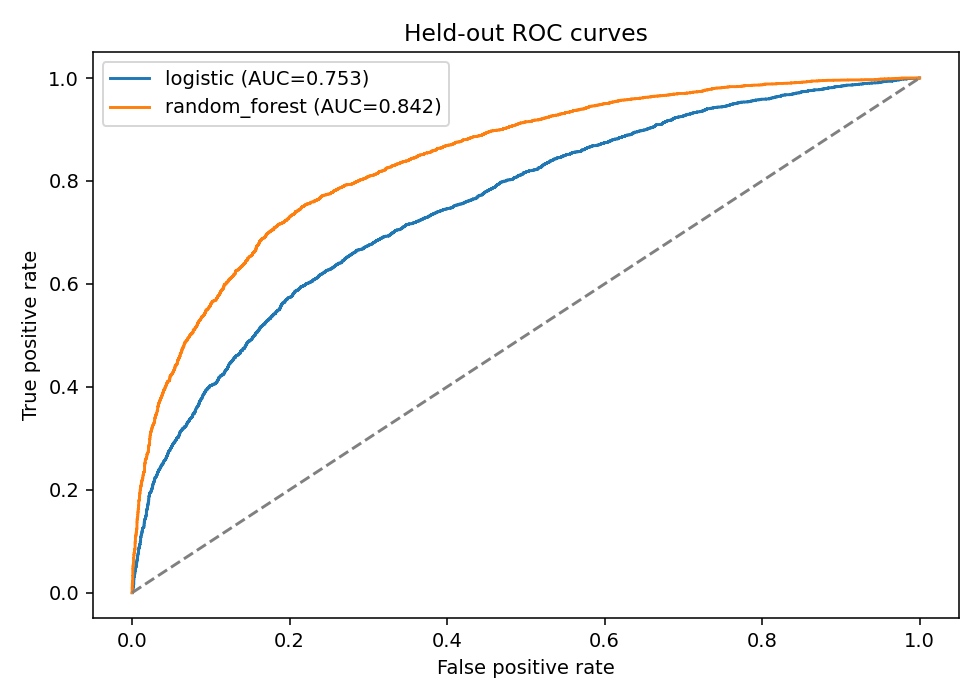

In [8]:
from IPython.display import display, Image
display(Image(filename="model_roc.png"))

## Part 3 — Feature importance
Permutation importance on held-out data ranks the strongest model signals.

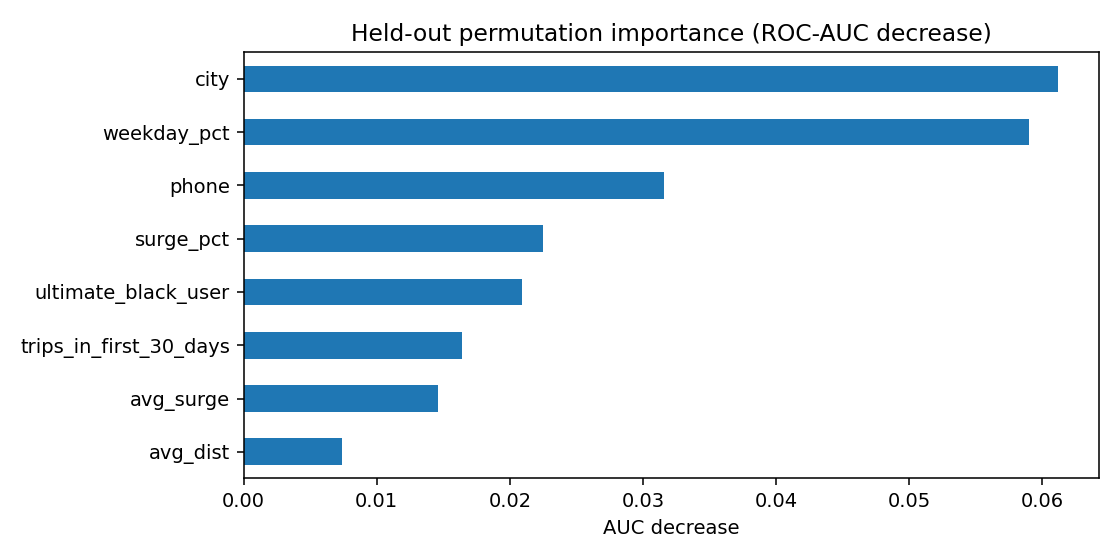

In [9]:
from IPython.display import display, Image
display(Image(filename="model_importance.png"))

## Part 2 — Toll reimbursement experiment

**Primary KPI:** share of eligible randomized drivers serving both cities in a fixed 7-day window. Randomize by driver, stratify on city and baseline driving, run four weeks, and use a two-proportion test plus baseline-adjusted logistic regression. Evaluate confidence intervals, cost per incremental cross-city driver, margin, rider wait time, cancellations, and marketplace interference. If driver-level spillovers are substantial, prefer a clustered/switchback experiment. Full implementation, tests and decision criteria are documented in `README.md`.

## Limitations and next steps

The supplied aggregates are not fully guaranteed to be point-in-time first-month features; validate feature availability before production. The train/test split estimates within-cohort generalization, not future-cohort generalization. No driver-level toll experiment data were supplied; Part 2 is a proposed experimental protocol, not a measured experiment.